# Лабораторная работа №2. Гистограммы, CDF, энтропия и коррекция контраста

Условие — в [методичке](CSE5382_15_лабораторных_работ_математические_методы_in_CV.md), раздел «Лабораторная работа №2».

**Данные.** `data/dark.jpg` — тёмный кадр 800×800 (уменьшенная копия `hw/cv/week02/img.jpg`). Тёмное изображение выбрано специально: на нём хорошо видно, что делают эквализация и гамма-коррекция.

## 1. О чём эта работа

### Знакомый пример

Вы сфотографировали комнату вечером: всё тёмное, деталей не видно. В телефоне есть ползунок «яркость/контраст» и кнопка «автоулучшение». Эта работа — о том, что именно делает такая кнопка и как измерить результат числом.

### Основная идея

Посчитаем, сколько в картинке пикселей каждой яркости. Получится столбчатая диаграмма — **гистограмма**. У тёмной фотографии почти все столбики сгрудились слева, а правая часть шкалы пустует. «Улучшить контраст» значит растянуть эту кучу на всю шкалу: часто встречающимся яркостям дать больше места, редким — меньше.

### Понятия

- **Гистограмма** $n_k$ — число пикселей с яркостью $k$ (для 8-битной картинки $k=0..255$).
- **Вероятность** $p_k=n_k/N$ — доля таких пикселей. Все $p_k\ge0$ и в сумме дают 1, поэтому это настоящее дискретное распределение: «с какой вероятностью случайно выбранный пиксель имеет яркость $k$».
- **CDF** (накопленная функция распределения) — доля пикселей с яркостью *не больше* $k$: $\mathrm{CDF}(k)=\sum_{i\le k}p_i$. Она только растёт и заканчивается единицей.
- **LUT** (look-up table, таблица подстановки) — массив из 256 чисел: «старую яркость $k$ заменить на `lut[k]`». Любое поточечное преобразование яркости — это одна такая таблица.
- **Энтропия Шеннона** — сколько в среднем бит нужно, чтобы закодировать яркость одного пикселя. Если все пиксели одинаковые — 0 бит (гадать нечего). Если все 256 уровней встречаются одинаково часто — 8 бит (максимум).

### Формулы

$$p_k=\frac{n_k}{N},\qquad H=-\sum_k p_k\log_2 p_k$$

Слагаемое $-\log_2 p_k$ — «удивление» от уровня $k$: редкий уровень удивляет сильно. Энтропия — среднее удивление. Уровни с $p_k=0$ пропускаем (считается, что $0\cdot\log0=0$).

**Эквализация гистограммы:**

$$s_k=\mathrm{round}\big((L-1)\cdot\mathrm{CDF}(r_k)\big)$$

$r_k$ — старый уровень, $s_k$ — новый, $L$ — число уровней (256). Смысл: если 60 % пикселей темнее данного, поставим его на 60 % шкалы. Тогда пиксели распределятся по шкале примерно равномерно.

**Гамма-коррекция:**

$$y=255\cdot\left(\frac{x}{255}\right)^{\gamma}$$

Сначала яркость переводится в диапазон 0..1, затем возводится в степень. Число меньше единицы в степени $\gamma<1$ увеличивается (картинка светлеет), в степени $\gamma>1$ уменьшается (темнеет). 0 и 255 остаются на месте.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.dpi": 80, "image.cmap": "gray"})

IMAGE_PATH = "data/dark.jpg"
GAMMAS = [0.5, 0.8, 1.2, 2.0]

## 2. Вопрос 1 — вероятности и энтропия

> Уровни 0,1,2,3 встречаются 2,2,4,8 раз. Найдите $p_k$ и энтропию H.

**Шаг 1.** Всего пикселей $N=2+2+4+8=16$.

**Шаг 2.** Вероятности: $p=[2/16,\ 2/16,\ 4/16,\ 8/16]=[0.125,\ 0.125,\ 0.25,\ 0.5]$. Проверка: сумма равна 1.

**Шаг 3.** Логарифмы по основанию 2. Все вероятности — степени двойки: $0.125=2^{-3}$, $0.25=2^{-2}$, $0.5=2^{-1}$, поэтому $\log_2$ равны $-3,-3,-2,-1$.

**Шаг 4.** Энтропия:

$$H=-\big[0.125\cdot(-3)+0.125\cdot(-3)+0.25\cdot(-2)+0.5\cdot(-1)\big]=0.375+0.375+0.5+0.5=1.75\ \text{бит}$$

**Смысл.** Уровней четыре, и при равных вероятностях было бы $\log_2 4=2$ бита. У нас меньше, потому что половина пикселей имеет один и тот же уровень 3 — угадывать яркость проще. Это буквально длина оптимального кода: уровень 3 кодируем одним битом, уровень 2 — двумя, уровни 0 и 1 — тремя; в среднем $0.5\cdot1+0.25\cdot2+0.25\cdot3=1.75$.

In [2]:
def entropy_from_counts(counts):
    p = np.asarray(counts, dtype=np.float64)
    p = p / p.sum()
    p = p[p > 0]                      # 0·log 0 считаем нулём
    return -(p * np.log2(p)).sum()

counts = np.array([2, 2, 4, 8])
p = counts / counts.sum()
print("N =", counts.sum())
print("p_k        :", p, " сумма =", p.sum())
print("log2 p_k   :", np.log2(p))
print("−p·log2 p  :", -p * np.log2(p))
print("H          :", entropy_from_counts(counts), "бит")
print("максимум для 4 уровней:", np.log2(4), "бит")

N = 16
p_k        : [0.125 0.125 0.25  0.5  ]  сумма = 1.0
log2 p_k   : [-3. -3. -2. -1.]
−p·log2 p  : [0.375 0.375 0.5   0.5  ]
H          : 1.75 бит
максимум для 4 уровней: 2.0 бит


**Итог вопроса 1:** $p=[0.125, 0.125, 0.25, 0.5]$, $H=1.75$ бит.

## 3. Вопрос 2 — эквализация и гамма

> Для L=8 и p=[0.05,0.10,0.20,0.25,0.40] рассчитайте CDF и новые уровни equalization. Затем для x=64 сравните gamma correction при γ=0.5 и γ=2.

**Замечание к условию.** Сказано $L=8$ (уровни 0..7), а вероятностей дано пять, и их сумма уже равна 1. Значит, это уровни 0..4, а уровни 5, 6, 7 в изображении не встречаются — картинка тёмная и использует только нижнюю часть шкалы.

### Эквализация

**Шаг 1. CDF** — накапливаем сумму слева направо:

| уровень $r_k$ | 0 | 1 | 2 | 3 | 4 |
|---|---|---|---|---|---|
| $p_k$ | 0.05 | 0.10 | 0.20 | 0.25 | 0.40 |
| CDF | 0.05 | 0.15 | 0.35 | 0.60 | 1.00 |
| $7\cdot$CDF | 0.35 | 1.05 | 2.45 | 4.20 | 7.00 |
| $s_k$ (округление) | 0 | 1 | 2 | 4 | 7 |

**Шаг 2.** Умножаем на $L-1=7$ и округляем до ближайшего целого.

**Что произошло.** Было занято 5 уровней из 8 (0..4), стало занято тоже 5, но теперь они растянуты до конца шкалы: 0, 1, 2, 4, 7. Самый частый уровень 4 (40 % пикселей) уехал дальше всех от соседа — с 4 на 7, расстояние между ним и предыдущим стало 3 вместо 1. Именно так эквализация повышает контраст: частым уровням даёт больше места.

Число занятых уровней не выросло: LUT отправляет одинаковые яркости в одну и ту же новую яркость, поэтому эквализация не может «разделить» столбик гистограммы, только переставить.

### Гамма для x = 64

$x/255=64/255\approx0.25098$.

- $\gamma=0.5$ — это квадратный корень: $\sqrt{0.25098}\approx0.50098$, $y\approx255\cdot0.50098\approx127.75\to128$.
- $\gamma=2$ — это квадрат: $0.25098^2\approx0.06299$, $y\approx255\cdot0.06299\approx16.06\to16$.

Тёмный пиксель 64 при $\gamma=0.5$ стал вдвое светлее (128), при $\gamma=2$ — вчетверо темнее (16). $\gamma<1$ растягивает тёмный участок шкалы и сжимает светлый; $\gamma>1$ — наоборот.

CDF        : [0.05 0.15 0.35 0.6  1.  ]
(L−1)·CDF  : [0.35 1.05 2.45 4.2  7.  ]
s_k        : [0 1 2 4 7]
γ=0.5: (x/255)^γ = 0.50098, y = 127.75 → 128
γ=2.0: (x/255)^γ = 0.06299, y = 16.06 → 16


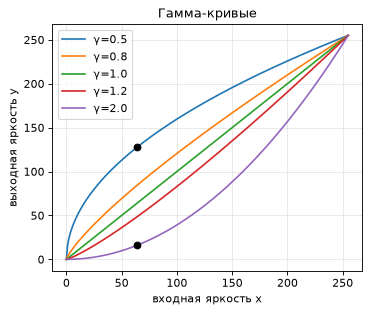

In [3]:
L = 8
p5 = np.array([0.05, 0.10, 0.20, 0.25, 0.40])
cdf5 = np.cumsum(p5)
print("CDF        :", cdf5)
print("(L−1)·CDF  :", (L - 1) * cdf5)
print("s_k        :", np.rint((L - 1) * cdf5).astype(int))

x = 64
for g in (0.5, 2.0):
    y = 255 * (x / 255) ** g
    print(f"γ={g}: (x/255)^γ = {(x / 255) ** g:.5f}, y = {y:.2f} → {round(y)}")

xs = np.arange(256)
plt.figure(figsize=(5, 4))
for g in [0.5, 0.8, 1.0, 1.2, 2.0]:
    plt.plot(xs, 255 * (xs / 255) ** g, label=f"γ={g}")
plt.scatter([64, 64], [255 * (64 / 255) ** 0.5, 255 * (64 / 255) ** 2], color="k", zorder=3)
plt.title("Гамма-кривые"); plt.xlabel("входная яркость x"); plt.ylabel("выходная яркость y")
plt.legend(); plt.grid(alpha=0.3); plt.show()

**Итог вопроса 2:** новые уровни `[0, 1, 2, 4, 7]`; $y\approx128$ при $\gamma=0.5$ и $y\approx16$ при $\gamma=2$.

## 4. Задание 3 — код и эксперимент

### Шаги 1–4. Grayscale, гистограмма через `np.bincount`, вероятности, энтропия

`np.bincount` считает, сколько раз встретилось каждое целое число, — это и есть гистограмма. `minlength=256` гарантирует 256 ячеек, даже если ярких пикселей нет.

In [4]:
gray = cv2.imread(IMAGE_PATH, cv2.IMREAD_GRAYSCALE)
assert gray is not None and gray.dtype == np.uint8
print("shape:", gray.shape, "dtype:", gray.dtype)

def entropy_u8(g):
    hist = np.bincount(g.ravel(), minlength=256).astype(np.float64)
    return entropy_from_counts(hist)

hist = np.bincount(gray.ravel(), minlength=256)
p = hist / hist.sum()
print("сумма p(k) =", p.sum())
print("занято уровней:", (hist > 0).sum(), "из 256")
print("mean =", round(gray.mean(), 2), " std =", round(gray.std(), 2), " entropy =", round(entropy_u8(gray), 4), "бит")
print("доля пикселей темнее 64:", round(p[:64].sum(), 3))

shape: (800, 800) dtype: uint8
сумма p(k) = 1.0
занято уровней: 255 из 256
mean = 42.07  std = 36.01  entropy = 6.4832 бит
доля пикселей темнее 64: 0.831


### Шаги 5–6. CDF, LUT и применение через индексирование

`lut[gray]` — «fancy indexing» NumPy: каждое значение пикселя используется как номер ячейки в таблице. Никаких циклов по пикселям.

In [5]:
cdf = np.cumsum(p)
lut = np.rint(255 * cdf).clip(0, 255).astype(np.uint8)
eq_manual = lut[gray]

print("CDF монотонна:", bool(np.all(np.diff(cdf) >= 0)), " CDF(255) =", cdf[-1])
print("LUT монотонна:", bool(np.all(np.diff(lut.astype(int)) >= 0)))
print("lut[0], lut[32], lut[64], lut[128], lut[255] =", lut[[0, 32, 64, 128, 255]])

CDF монотонна: True  CDF(255) = 0.9999999999999999
LUT монотонна: True
lut[0], lut[32], lut[64], lut[128], lut[255] = [  0 131 213 245 255]


### Шаг 7. Сравнение с `cv2.equalizeHist`

OpenCV использует чуть другую формулу: вычитает из CDF её первое ненулевое значение и делит на остаток,

$$s_k=\mathrm{round}\Big(255\cdot\frac{\mathrm{CDF}(k)-\mathrm{CDF}_{min}}{1-\mathrm{CDF}_{min}}\Big)$$

чтобы самый тёмный из присутствующих уровней попадал точно в 0. Формула методички отправляет его в $255\cdot\mathrm{CDF}_{min}$. Если самых тёмных пикселей мало ($\mathrm{CDF}_{min}\approx0$), обе формулы дают одно и то же; если много — результаты расходятся. Ниже реализованы обе формулы и проверены на двух картинках: на нашем кадре и на его версии, где 30 % пикселей принудительно сделаны чёрными.

CDF_min = 1.56e-06
MAE (формула методички vs OpenCV)       : 0.0  max |Δ| = 0
MAE (формула с вычитанием CDF_min vs CV): 0.0  max |Δ| = 0

контрольный пример: CDF_min = 0.316
  MAE (формула методички vs OpenCV)       : 52.603  чёрное → 81 вместо 0
  MAE (формула с вычитанием CDF_min vs CV): 0.0


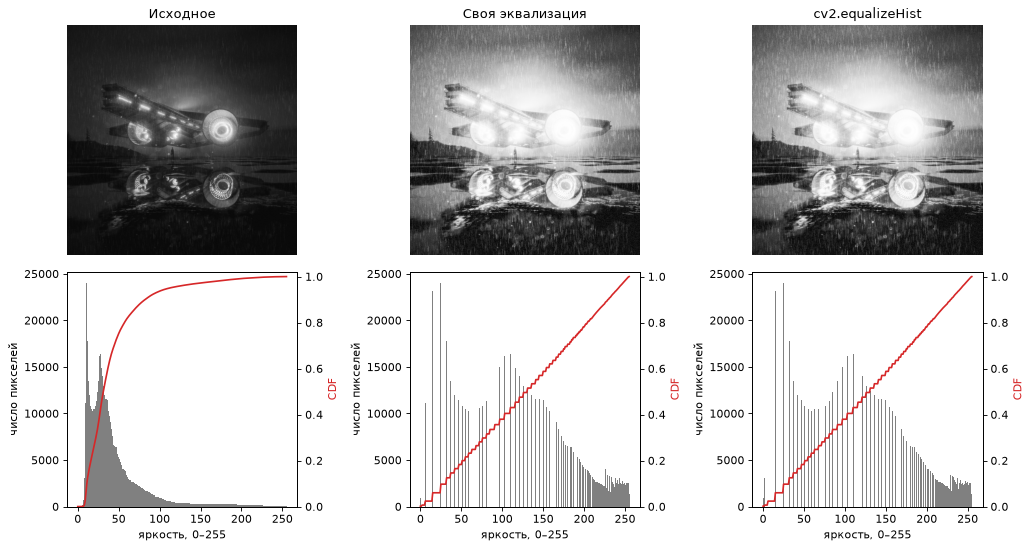

In [6]:
eq_cv = cv2.equalizeHist(gray)

cdf_min = cdf[np.nonzero(hist)[0][0]]
lut_cv_like = np.rint(255 * (cdf - cdf_min) / (1 - cdf_min)).clip(0, 255).astype(np.uint8)
eq_cv_like = lut_cv_like[gray]

def mae(a, b):
    return np.abs(a.astype(float) - b.astype(float)).mean()

print(f"CDF_min = {cdf_min:.2e}")
print("MAE (формула методички vs OpenCV)       :", round(mae(eq_manual, eq_cv), 4), " max |Δ| =", int(np.abs(eq_manual.astype(int) - eq_cv).max()))
print("MAE (формула с вычитанием CDF_min vs CV):", round(mae(eq_cv_like, eq_cv), 4), " max |Δ| =", int(np.abs(eq_cv_like.astype(int) - eq_cv).max()))

# контрольный пример, где CDF_min большая: 30 % самых тёмных пикселей сделаны нулём
g2 = gray.copy(); g2[g2 <= np.quantile(gray, 0.30)] = 0
h2 = np.bincount(g2.ravel(), minlength=256); c2 = np.cumsum(h2 / h2.sum()); cmin2 = c2[0]
eq2_manual = np.rint(255 * c2).astype(np.uint8)[g2]
eq2_like = np.rint(255 * (c2 - cmin2) / (1 - cmin2)).clip(0, 255).astype(np.uint8)[g2]
eq2_cv = cv2.equalizeHist(g2)
print(f"\nконтрольный пример: CDF_min = {cmin2:.3f}")
print("  MAE (формула методички vs OpenCV)       :", round(mae(eq2_manual, eq2_cv), 3), " чёрное →", eq2_manual.min(), "вместо", eq2_cv.min())
print("  MAE (формула с вычитанием CDF_min vs CV):", round(mae(eq2_like, eq2_cv), 3))

fig, ax = plt.subplots(2, 3, figsize=(13, 7))
for j, (im, title) in enumerate([(gray, "Исходное"), (eq_manual, "Своя эквализация"), (eq_cv, "cv2.equalizeHist")]):
    ax[0, j].imshow(im, vmin=0, vmax=255); ax[0, j].set_title(title); ax[0, j].axis("off")
    h = np.bincount(im.ravel(), minlength=256)
    ax[1, j].bar(np.arange(256), h, width=1.0, color="gray")
    ax2 = ax[1, j].twinx(); ax2.plot(np.cumsum(h) / h.sum(), color="tab:red"); ax2.set_ylim(0, 1.02)
    ax[1, j].set_xlabel("яркость, 0–255"); ax[1, j].set_ylabel("число пикселей"); ax2.set_ylabel("CDF", color="tab:red")
plt.tight_layout(); plt.show()

Красная линия — CDF. У исходного кадра она взлетает почти вертикально в тёмной области; после эквализации становится близка к диагонали — это и есть «равномерное распределение».

### Шаги 8–9. Гамма-коррекция и таблица эксперимента

Гамма тоже реализована через LUT: формула считается один раз для 256 значений, а не для каждого пикселя.

Метод/γ                  Mean      Std   Entropy  Уровней   Std в тёмном углу
исходное                42.07    36.01    6.4832      255                3.61
equalize (своя)        129.49    72.57    6.2493      100               19.69
equalize (OpenCV)      129.49    72.57    6.2493      100               19.69
γ=0.5                   96.64    37.17    6.4187      191                5.47
γ=0.8                   57.75    37.70    6.4686      234                4.47
γ=1.2                   31.39    33.83    6.0886      239                2.83
γ=2.0                   12.02    26.01    4.6725      192                0.86


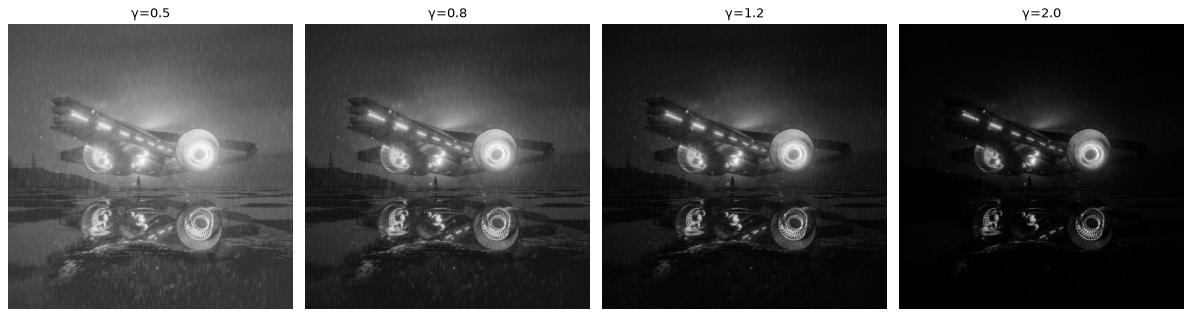

In [7]:
def gamma_lut(g):
    xs = np.arange(256) / 255.0
    return np.rint(255 * xs ** g).clip(0, 255).astype(np.uint8)

variants = {"исходное": gray, "equalize (своя)": eq_manual, "equalize (OpenCV)": eq_cv}
for g in GAMMAS:
    variants[f"γ={g}"] = gamma_lut(g)[gray]

noise_region = (slice(0, 120), slice(0, 120))   # почти чёрный угол: здесь виден только шум
print(f"{'Метод/γ':20}{'Mean':>9}{'Std':>9}{'Entropy':>10}{'Уровней':>9}{'Std в тёмном углу':>20}")
rows = {}
for name, im in variants.items():
    rows[name] = (im.mean(), im.std(), entropy_u8(im), int((np.bincount(im.ravel(), minlength=256) > 0).sum()), im[noise_region].std())
    print(f"{name:20}{rows[name][0]:9.2f}{rows[name][1]:9.2f}{rows[name][2]:10.4f}{rows[name][3]:9d}{rows[name][4]:20.2f}")

fig, ax = plt.subplots(1, 4, figsize=(15, 4))
for a, g in zip(ax, GAMMAS):
    a.imshow(variants[f"γ={g}"], vmin=0, vmax=255); a.set_title(f"γ={g}"); a.axis("off")
plt.tight_layout(); plt.show()

Столбец «Std в тёмном углу» — стандартное отклонение яркости в углу 120×120, где на исходном кадре нет деталей, только шум сенсора и JPEG. Чем это число больше, тем сильнее усилен шум.

## 5. Неудачный случай: энтропия выросла, а картинка стала хуже

Проверим прямо: добавим к исходному изображению гауссов шум. Полезной информации о сцене не прибавилось, но гистограмма расползлась — и энтропия выросла.

entropy исходного    : 6.4832
entropy с шумом σ=25 : 6.6098
entropy перемешанных пикселей: 6.4832 (та же гистограмма → та же энтропия)


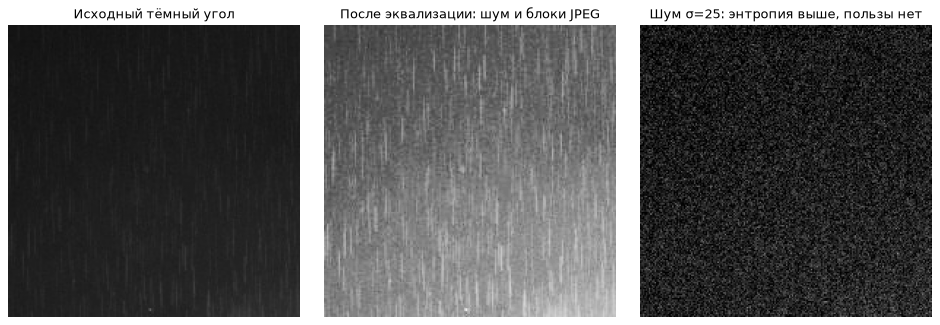

In [8]:
rng = np.random.default_rng(0)
noisy = np.clip(gray.astype(float) + rng.normal(0, 25, gray.shape), 0, 255).astype(np.uint8)
print("entropy исходного    :", round(entropy_u8(gray), 4))
print("entropy с шумом σ=25 :", round(entropy_u8(noisy), 4))
print("entropy перемешанных пикселей:", round(entropy_u8(rng.permutation(gray.ravel()).reshape(gray.shape)), 4), "(та же гистограмма → та же энтропия)")

crop = (slice(0, 200), slice(0, 200))
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
ax[0].imshow(gray[crop], vmin=0, vmax=255); ax[0].set_title("Исходный тёмный угол")
ax[1].imshow(eq_manual[crop], vmin=0, vmax=255); ax[1].set_title("После эквализации: шум и блоки JPEG")
ax[2].imshow(noisy[crop], vmin=0, vmax=255); ax[2].set_title("Шум σ=25: энтропия выше, пользы нет")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

Два наблюдения.

1. **Шум повышает энтропию.** Энтропия измеряет только форму гистограммы. Она не знает, что именно закодировано — детали сцены или случайный шум. Если перемешать все пиксели случайным образом, картинка превратится в «снег», а энтропия не изменится вовсе.
2. **Эквализация усиливает шум в тёмных областях.** Тёмных пикселей много, значит CDF там растёт круто, значит соседние тёмные уровни разъезжаются далеко друг от друга. Незаметная разница «3 против 5» превращается в заметную — проявляются шум и блочная структура JPEG.

## 6. Вывод

Цифры относятся к `data/dark.jpg`.

- Исходный кадр тёмный: средняя яркость ≈ 42 из 255, и 83 % пикселей темнее 64. Гистограмма сжата у левого края.
- После эквализации среднее выросло до ≈ 129.5 (середина шкалы, как и должно быть при равномерном распределении), std — с ≈ 36 до ≈ 73: контраст вырос вдвое, детали в тенях стали видны.
- **Энтропия после эквализации не выросла, а упала**: 6.48 → 6.25 бит. Это не ошибка. LUT — функция от яркости: разные уровни могут слиться в один (при округлении), но один уровень не может разделиться на два. Число занятых уровней уменьшилось с 255 до 100. Эквализация делает гистограмму более *растянутой*, а не более *разнообразной*.
- Гамма: $\gamma=0.5$ осветляет (mean 42 → 97), $\gamma=2$ затемняет (mean ≈ 12) и схлопывает тени — энтропия падает до ≈ 4.67 бит. $\gamma=0.8$ и $\gamma=1.2$ — мягкие версии того же. Std при гамме меняется мало (26–38): гамма сдвигает яркость, но не растягивает гистограмму так, как эквализация.
- Собственная эквализация на этом кадре совпала с `cv2.equalizeHist` точно (MAE = 0): самых тёмных пикселей почти нет, $\mathrm{CDF}_{min}\approx0$, и обе формулы дают одно и то же. На контрольном примере с 30 % чёрных пикселей формула методички расходится с OpenCV (чёрное уходит в серое 81, MAE ≈ 53), а формула с вычитанием $\mathrm{CDF}_{min}$ совпадает точно.
- Всегда ли большая энтропия означает более полезное изображение? **Нет.** Шум σ=25 поднял энтропию с 6.48 до 6.61 бит, ничего не добавив к содержанию; эквализация, наоборот, снизила энтропию, но сделала картинку заметно информативнее для глаза. При этом эквализация подняла разброс в пустом тёмном углу с ≈ 3.6 до ≈ 19.7 уровня — усилила шум в пять раз. Энтропия описывает гистограмму, а не качество.

## 7. Вопросы на защиту

**1. Почему p(k) можно интерпретировать как дискретное распределение вероятностей?**
Потому что $p_k=n_k/N\ge0$ и $\sum_k p_k=\sum_k n_k/N=N/N=1$. Это вероятность того, что случайно (равновероятно) выбранный пиксель имеет яркость $k$. Распределение *эмпирическое* — оно описывает данную картинку, а не «все возможные картинки».

**2. Почему увеличение энтропии не гарантирует лучшего изображения для CV-задачи?**
Энтропия зависит только от гистограммы и не зависит от расположения пикселей: перемешанная картинка имеет ту же энтропию. Шум энтропию увеличивает. Для задачи важны структуры (границы, текстуры объекта), а не число занятых уровней. Кроме того, глобальная эквализация может пересветить важную область или усилить шум в тенях.

**3. Код формирования LUT; почему CDF задаёт монотонное отображение.**
`cdf = np.cumsum(p)` — накопленная сумма неотрицательных чисел, поэтому каждое следующее значение не меньше предыдущего. `lut = np.rint(255 * cdf)` — умножение на положительное число и округление порядок не нарушают. Значит, если пиксель A был темнее пикселя B, после преобразования он не станет светлее: порядок яркостей сохраняется, меняются только расстояния между уровнями. `lut[gray]` применяет таблицу ко всем пикселям сразу.